# Práctica: LSTM con atención de Bahdanau

**Procesamiento del Lenguaje Natural**

Partimos del modelo seq2seq con LSTM visto en clase (traducción inglés → español, `nb05`) y le añadimos el mecanismo de atención aditiva de Bahdanau et al. (2014), tal y como se plantea en `nb06`.

En un seq2seq clásico el decodificador solo recibe el último estado del codificador, un único vector de tamaño fijo. Con atención, en cada paso $i$ el decodificador recalcula un **vector de contexto** $c_i$ como media ponderada de *todas* las anotaciones del codificador:

$$c_i=\sum_{j=1}^{T_x}\alpha_{ij}\,h_j,\qquad \alpha_{ij}=\frac{\exp(e_{ij})}{\sum_{k=1}^{T_x}\exp(e_{ik})},\qquad e_{ij}=v_a^{\top}\tanh\big(W_1[s_{i-1};h_j]\big)$$

Contenido del notebook:

1. Datos, tokenización y vocabulario.
2. Codificador LSTM (devuelve todas las anotaciones $h_j$).
3. **Módulo de atención de Bahdanau** (lo nuevo).
4. Decodificador con atención y modelo `Seq2Seq`.
5. Entrenamiento: modelo **sin atención** (baseline de `nb05`) frente a modelo **con atención**.
6. Evaluación (pérdida, BLEU, BLEU según longitud) y visualización de la alineación $\alpha_{ij}$.

## 0. Configuración

In [1]:
import math, random, time, re, os, collections
import torch, torch.nn as nn, torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence, pad_sequence
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DEVICE)

# --- Datos -----------------------------------------------------------------
# Si existen los ficheros paralelos de Europarl (una frase por línea, alineadas),
# se usan. En caso contrario se genera un corpus sintético inglés->español
# (ver sección 1) para que el notebook se pueda ejecutar de principio a fin.
SRC_FILE = "europarl-v7.es-en.en"
TGT_FILE = "europarl-v7.es-en.es"
MAX_PAIRS  = 100_000      # nº máximo de pares a leer de Europarl
MAX_LEN    = 30           # longitud máxima (en tokens) al filtrar Europarl
MIN_FREQ   = 2            # frecuencia mínima para entrar en el vocabulario
MAX_VOCAB  = 10_000

# --- Modelo ----------------------------------------------------------------
EMB_DIM    = 64
HID_DIM    = 128          # dimensión del estado del decodificador (s_i)
ATTN_DIM   = 64           # dimensión intermedia de la atención (salida de W1)
BIDIR      = True         # codificador bidireccional (como en el artículo original)
DROPOUT    = 0.1

# --- Entrenamiento ---------------------------------------------------------
BATCH_SIZE = 64
EPOCHS     = 12
LR         = 2e-3
CLIP       = 1.0
TEACHER_FORCING = 0.5     # fracción de pasos con teacher forcing

Dispositivo: cpu


## 1. Datos, tokenización y vocabulario

La tokenización es la sencilla de clase: minúsculas, palabras y signos de puntuación por separado. Los cuatro tokens especiales son `<pad>`, `<sos>`, `<eos>` y `<unk>`.

**Corpus sintético de respaldo.** Si no están los ficheros de Europarl se genera un corpus de frases del tipo
`the big red car sees the small dog` → `el coche grande rojo ve el perro pequeño`.
Está pensado para que la atención tenga algo que aprender: en español el adjetivo va detrás del sustantivo, el orden de los adjetivos se invierte y el artículo concuerda en género. Por tanto, la alineación **no** es monótona.

In [2]:
PAD, SOS, EOS, UNK = "<pad>", "<sos>", "<eos>", "<unk>"
SPECIALS = [PAD, SOS, EOS, UNK]

def tokenize(s):
    return re.findall(r"\w+|[^\w\s]", s.lower())

def load_europarl(src_file, tgt_file, max_pairs, max_len):
    pairs, seen = [], set()
    with open(src_file, encoding="utf-8") as fs, open(tgt_file, encoding="utf-8") as ft:
        for s, t in zip(fs, ft):
            s, t = tokenize(s), tokenize(t)
            if not (1 <= len(s) <= max_len and 1 <= len(t) <= max_len):
                continue
            key = (tuple(s), tuple(t))
            if key in seen:
                continue
            seen.add(key); pairs.append((s, t))
            if len(pairs) >= max_pairs:
                break
    return pairs

# ---- corpus sintético ----
NOUNS = [("car","coche","m"),("dog","perro","m"),("man","hombre","m"),("house","casa","f"),
         ("cat","gato","m"),("woman","mujer","f"),("book","libro","m"),("table","mesa","f"),
         ("boy","niño","m"),("girl","niña","f"),("garden","jardín","m"),("window","ventana","f")]
ADJS  = [("big","grande","grande"),("small","pequeño","pequeña"),("red","rojo","roja"),
         ("old","viejo","vieja"),("new","nuevo","nueva"),("black","negro","negra"),
         ("white","blanco","blanca"),("green","verde","verde")]
VERBS = [("sees","ve"),("buys","compra"),("wants","quiere"),("finds","encuentra"),("has","tiene")]

def np_pair(rng):
    en, es, g = rng.choice(NOUNS)
    k = rng.choice([0, 1, 1, 2])                       # 0, 1 o 2 adjetivos
    adjs = rng.sample(ADJS, k)
    art_es = "el" if g == "m" else "la"
    en_np = ["the"] + [a[0] for a in adjs] + [en]
    es_np = [art_es, es] + [a[1] if g == "m" else a[2] for a in reversed(adjs)]
    return en_np, es_np

def make_toy_corpus(n, seed=0):
    rng, pairs, seen = random.Random(seed), [], set()
    while len(pairs) < n:
        e1, s1 = np_pair(rng); e2, s2 = np_pair(rng)
        en_v, es_v = rng.choice(VERBS)
        pair = (e1 + [en_v] + e2 + ["."], s1 + [es_v] + s2 + ["."])
        if tuple(pair[0]) in seen: continue
        seen.add(tuple(pair[0])); pairs.append(pair)
    return pairs

if os.path.exists(SRC_FILE) and os.path.exists(TGT_FILE):
    pairs = load_europarl(SRC_FILE, TGT_FILE, MAX_PAIRS, MAX_LEN)
    CORPUS = "Europarl"
else:
    pairs = make_toy_corpus(20_000)
    CORPUS = "sintético"
print(f"Corpus {CORPUS}: {len(pairs)} pares")
for s, t in pairs[:3]:
    print(" ".join(s), "->", " ".join(t))

Corpus sintético: 20000 pares
the big red book wants the white green boy . -> el libro rojo grande quiere el niño verde blanco .
the old table buys the new boy . -> la mesa vieja compra el niño nuevo .
the red dog sees the cat . -> el perro rojo ve el gato .


In [3]:
# Partición agrupando por frase de origen (evita que la misma frase caiga en train y test)
by_src = collections.defaultdict(list)
for s, t in pairs:
    by_src[tuple(s)].append((s, t))
keys = sorted(by_src); random.Random(SEED).shuffle(keys)
n = len(keys); n_val = n_test = max(1, int(0.05 * n))
split = lambda ks: [p for k in ks for p in by_src[k]]
test_pairs  = split(keys[:n_test])
val_pairs   = split(keys[n_test:n_test + n_val])
train_pairs = split(keys[n_test + n_val:])
print(len(train_pairs), len(val_pairs), len(test_pairs))

class Vocab:
    def __init__(self, sentences, min_freq, max_size):
        cnt = collections.Counter(w for s in sentences for w in s)
        words = [w for w, c in cnt.most_common() if c >= min_freq][: max_size - len(SPECIALS)]
        self.itos = SPECIALS + words
        self.stoi = {w: i for i, w in enumerate(self.itos)}
    def encode(self, toks): return [self.stoi.get(w, self.stoi[UNK]) for w in toks]
    def decode(self, ids):  return [self.itos[i] for i in ids]
    def __len__(self): return len(self.itos)

src_vocab = Vocab([s for s, _ in train_pairs], MIN_FREQ, MAX_VOCAB)
tgt_vocab = Vocab([t for _, t in train_pairs], MIN_FREQ, MAX_VOCAB)
PAD_ID, SOS_ID, EOS_ID, UNK_ID = (tgt_vocab.stoi[x] for x in SPECIALS)
print("Vocabulario origen:", len(src_vocab), "| destino:", len(tgt_vocab))

class PairDataset(Dataset):
    def __init__(self, pairs): self.pairs = pairs
    def __len__(self): return len(self.pairs)
    def __getitem__(self, i):
        s, t = self.pairs[i]
        return (torch.tensor(src_vocab.encode(s) + [EOS_ID]),
                torch.tensor([SOS_ID] + tgt_vocab.encode(t) + [EOS_ID]))

def collate(batch):
    src, tgt = zip(*batch)
    src_len = torch.tensor([len(x) for x in src])
    return (pad_sequence(src, batch_first=True, padding_value=PAD_ID), src_len,
            pad_sequence(tgt, batch_first=True, padding_value=PAD_ID))

mk = lambda p, shuf: DataLoader(PairDataset(p), batch_size=BATCH_SIZE, shuffle=shuf, collate_fn=collate)
train_dl, val_dl, test_dl = mk(train_pairs, True), mk(val_pairs, False), mk(test_pairs, False)

18000 1000 1000
Vocabulario origen: 31 | destino: 38


## 2. Codificador

LSTM (bidireccional por defecto, como en el artículo) que ignora el relleno con `pack_padded_sequence`. A diferencia del modelo sin atención, ahora **devolvemos todas las salidas** $h_1,\dots,h_{T_x}$ (las anotaciones), no solo el último estado. Cada $h_j$ concatena el estado hacia delante y hacia atrás, de dimensión `enc_dim = 2·hid` si es bidireccional.

El estado final del codificador se proyecta con una capa lineal a la dimensión del decodificador para inicializar $s_0$ (y la celda $c_0$).

In [4]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, enc_hid, dec_hid, bidirectional=True, dropout=0.1):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_ID)
        self.rnn = nn.LSTM(emb_dim, enc_hid, batch_first=True, bidirectional=bidirectional)
        self.bi = bidirectional
        self.enc_dim = enc_hid * (2 if bidirectional else 1)
        self.bridge_h = nn.Linear(self.enc_dim, dec_hid)
        self.bridge_c = nn.Linear(self.enc_dim, dec_hid)
        self.drop = nn.Dropout(dropout)

    def forward(self, src, src_len):
        x = self.drop(self.emb(src))
        packed = pack_padded_sequence(x, src_len.cpu(), batch_first=True, enforce_sorted=False)
        out, (h, c) = self.rnn(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=src.size(1))   # (B, Tx, enc_dim)
        if self.bi:                                   # h, c: (2, B, hid) -> (B, 2*hid)
            h, c = torch.cat([h[0], h[1]], -1), torch.cat([c[0], c[1]], -1)
        else:
            h, c = h[0], c[0]
        return out, (torch.tanh(self.bridge_h(h)), torch.tanh(self.bridge_c(c)))

## 3. Atención de Bahdanau

Es una implementación literal del enunciado. Para cada posición $j$ de la frase origen:

$$e_{ij}=v_a^{\top}\tanh\big(W_1[s_{i-1};h_j]\big)$$

- `W1` es una capa lineal sobre la **concatenación** $[s_{i-1};h_j]$, que la proyecta a un espacio intermedio (`attn_dim`).
- `tanh` introduce la no linealidad.
- `v` es un vector (capa lineal sin sesgo a 1 dimensión) que colapsa el resultado a un escalar $e_{ij}$.
- Los scores de las posiciones de **relleno** se ponen a $-\infty$ antes del softmax, para que $\alpha_{ij}=0$ allí.
- El contexto es $c_i=\sum_j\alpha_{ij}h_j$, que se calcula con un producto matricial por lotes (`torch.bmm`).

Nota: aplicar `W1` sobre la concatenación equivale a $W_s s_{i-1}+W_h h_j$ con $W_1=[W_s\,|\,W_h]$ (es la forma que usa el artículo y permite precalcular $W_h h_j$ una vez por frase). Aquí se mantiene la concatenación para que se vea igual que la fórmula.

In [5]:
class BahdanauAttention(nn.Module):
    def __init__(self, dec_hid, enc_dim, attn_dim):
        super().__init__()
        self.W1 = nn.Linear(dec_hid + enc_dim, attn_dim)     # actúa sobre [s_{i-1}; h_j]
        self.v = nn.Linear(attn_dim, 1, bias=False)          # v_a

    def forward(self, s_prev, enc_out, mask):
        # s_prev: (B, dec_hid) | enc_out: (B, Tx, enc_dim) | mask: (B, Tx) True = token real
        Tx = enc_out.size(1)
        s = s_prev.unsqueeze(1).expand(-1, Tx, -1)                          # (B, Tx, dec_hid)
        e = self.v(torch.tanh(self.W1(torch.cat([s, enc_out], dim=-1))))    # (B, Tx, 1)
        e = e.squeeze(-1).masked_fill(~mask, float("-inf"))                 # (B, Tx)
        alpha = F.softmax(e, dim=-1)                                        # (B, Tx)
        context = torch.bmm(alpha.unsqueeze(1), enc_out).squeeze(1)         # (B, enc_dim)
        return context, alpha

# Comprobación rápida de formas y de que las posiciones de relleno reciben peso 0
_att = BahdanauAttention(dec_hid=8, enc_dim=6, attn_dim=5)
_mask = torch.tensor([[1, 1, 1, 0], [1, 1, 0, 0]], dtype=torch.bool)
_c, _a = _att(torch.randn(2, 8), torch.randn(2, 4, 6), _mask)
print(_c.shape, _a.shape); print(_a); print("Suma de pesos:", _a.sum(-1))

torch.Size([2, 6]) torch.Size([2, 4])
tensor([[0.3613, 0.2804, 0.3583, 0.0000],
        [0.4286, 0.5714, 0.0000, 0.0000]], grad_fn=<SoftmaxBackward0>)
Suma de pesos: tensor([1., 1.], grad_fn=<SumBackward1>)


## 4. Decodificador con atención y modelo Seq2Seq

En cada paso $i$ el decodificador:

1. Usa su estado previo $s_{i-1}$ para calcular $\alpha_{i\cdot}$ y el contexto $c_i$.
2. Alimenta una `LSTMCell` con $[\,\text{emb}(y_{i-1});\,c_i\,]$ y obtiene $s_i$.
3. Predice $y_i$ a partir de $[\,s_i;\,c_i;\,\text{emb}(y_{i-1})\,]$ con una capa lineal.

Con `use_attention=False` el decodificador es el de `nb05`: el contexto es solo el estado inicial que viene del codificador. Así comparamos con exactamente la misma arquitectura salvo la atención.

El `Seq2Seq` implementa *teacher forcing* (por paso, con probabilidad `tf`) y generación voraz (*greedy*), que además devuelve los pesos de atención.

In [6]:
class Decoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, dec_hid, enc_dim, attn_dim, dropout=0.1, use_attention=True):
        super().__init__()
        self.use_attention = use_attention
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_ID)
        ctx = enc_dim if use_attention else 0
        self.attn = BahdanauAttention(dec_hid, enc_dim, attn_dim) if use_attention else None
        self.cell = nn.LSTMCell(emb_dim + ctx, dec_hid)
        self.out = nn.Linear(dec_hid + ctx + emb_dim, vocab_size)
        self.drop = nn.Dropout(dropout)

    def step(self, y_prev, state, enc_out, mask):
        h, c = state                                         # h = s_{i-1}
        e = self.drop(self.emb(y_prev))                      # (B, emb)
        if self.use_attention:
            ctx, alpha = self.attn(h, enc_out, mask)
            h, c = self.cell(torch.cat([e, ctx], -1), (h, c))
            logits = self.out(self.drop(torch.cat([h, ctx, e], -1)))
        else:
            alpha = None
            h, c = self.cell(e, (h, c))
            logits = self.out(self.drop(torch.cat([h, e], -1)))
        return logits, (h, c), alpha


class Seq2Seq(nn.Module):
    def __init__(self, src_vocab_size, tgt_vocab_size, use_attention=True):
        super().__init__()
        self.encoder = Encoder(src_vocab_size, EMB_DIM, HID_DIM, HID_DIM, BIDIR, DROPOUT)
        self.decoder = Decoder(tgt_vocab_size, EMB_DIM, HID_DIM, self.encoder.enc_dim,
                               ATTN_DIM, DROPOUT, use_attention)

    def forward(self, src, src_len, tgt, tf=0.5):
        # tgt: (B, Tt) con <sos> ... <eos>. Devuelve logits para tgt[:, 1:]
        enc_out, state = self.encoder(src, src_len)
        mask = src != PAD_ID
        y = tgt[:, 0]
        outs = []
        for t in range(1, tgt.size(1)):
            logits, state, _ = self.decoder.step(y, state, enc_out, mask)
            outs.append(logits)
            use_gold = random.random() < tf
            y = tgt[:, t] if use_gold else logits.argmax(-1)
        return torch.stack(outs, 1)                          # (B, Tt-1, V)

    @torch.no_grad()
    def generate(self, src, src_len, max_len=40):
        self.eval()
        enc_out, state = self.encoder(src, src_len)
        mask = src != PAD_ID
        B = src.size(0)
        y = torch.full((B,), SOS_ID, device=src.device)
        done = torch.zeros(B, dtype=torch.bool, device=src.device)
        toks, atts = [], []
        for _ in range(max_len):
            logits, state, alpha = self.decoder.step(y, state, enc_out, mask)
            y = logits.argmax(-1)
            toks.append(y)
            if alpha is not None: atts.append(alpha)
            done |= y == EOS_ID
            if done.all(): break
        toks = torch.stack(toks, 1).tolist()
        att = torch.stack(atts, 1) if atts else None         # (B, steps, Tx)
        out = []
        for row in toks:
            out.append(row[:row.index(EOS_ID)] if EOS_ID in row else row)
        return out, att

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

## 5. Entrenamiento

Pérdida de entropía cruzada ignorando el relleno (equivale a normalizar por el número de tokens válidos), Adam, recorte de gradientes y selección del mejor modelo según la pérdida de validación, igual que en `nb05`. Se entrenan dos modelos con las mismas semillas e hiperparámetros: **sin atención** y **con atención**.

In [7]:
def run_epoch(model, dl, opt=None, tf=0.0):
    train = opt is not None
    model.train(train)
    tot_loss, tot_tok = 0.0, 0
    with torch.set_grad_enabled(train):
        for src, src_len, tgt in dl:
            src, src_len, tgt = src.to(DEVICE), src_len.to(DEVICE), tgt.to(DEVICE)
            logits = model(src, src_len, tgt, tf=tf)
            gold = tgt[:, 1:]
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), gold.reshape(-1),
                                   ignore_index=PAD_ID, reduction="sum")
            ntok = (gold != PAD_ID).sum().item()
            if train:
                opt.zero_grad()
                (loss / ntok).backward()
                nn.utils.clip_grad_norm_(model.parameters(), CLIP)
                opt.step()
            tot_loss += loss.item(); tot_tok += ntok
    return tot_loss / tot_tok

def train_model(use_attention, name):
    torch.manual_seed(SEED); random.seed(SEED)
    model = Seq2Seq(len(src_vocab), len(tgt_vocab), use_attention).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    print(f"== {name} | parámetros: {count_params(model):,}")
    best, best_state, hist = float("inf"), None, []
    for ep in range(1, EPOCHS + 1):
        t0 = time.time()
        tr = run_epoch(model, train_dl, opt, tf=TEACHER_FORCING)
        va = run_epoch(model, val_dl, None, tf=0.0)
        hist.append((tr, va))
        if va < best:
            best, best_state = va, {k: v.detach().clone() for k, v in model.state_dict().items()}
        print(f"ép {ep:2d} | train {tr:.4f} | val {va:.4f} | ppl val {math.exp(va):.2f} | {time.time()-t0:.0f}s")
    model.load_state_dict(best_state)
    return model, hist

model_base, hist_base = train_model(False, "Sin atención (baseline)")
model_attn, hist_attn = train_model(True,  "Con atención de Bahdanau")

== Sin atención (baseline) | parámetros: 375,526


ép  1 | train 1.9989 | val 2.3072 | ppl val 10.05 | 10s


ép  2 | train 1.5093 | val 1.3028 | ppl val 3.68 | 9s


ép  3 | train 1.0959 | val 1.0537 | ppl val 2.87 | 9s


ép  4 | train 0.9794 | val 0.8869 | ppl val 2.43 | 9s


ép  5 | train 0.8476 | val 0.7803 | ppl val 2.18 | 9s


... (15 outputs left out)

ép  9 | train 0.0001 | val 0.0000 | ppl val 1.00 | 15s


ép 10 | train 0.0014 | val 0.0001 | ppl val 1.00 | 17s


ép 11 | train 0.0001 | val 0.0000 | ppl val 1.00 | 17s


ép 12 | train 0.0001 | val 0.0000 | ppl val 1.00 | 15s


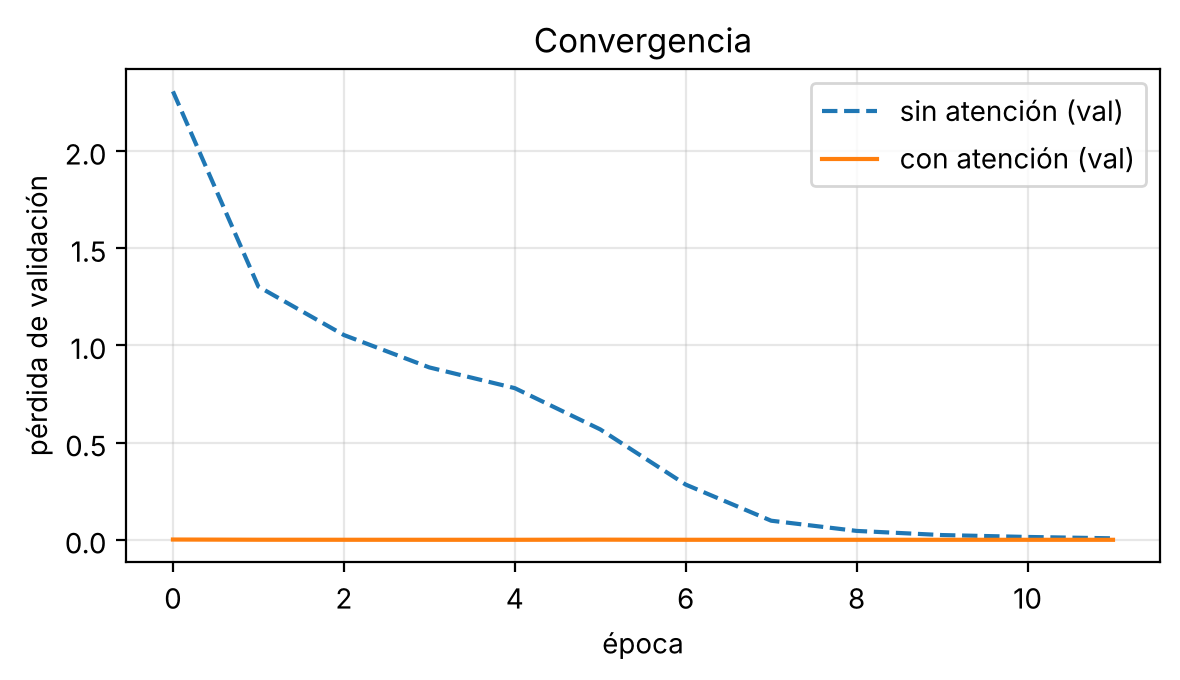

In [8]:
plt.figure(figsize=(6, 3.5))
for h, lab, st in [(hist_base, "sin atención", "--"), (hist_attn, "con atención", "-")]:
    plt.plot([v for _, v in h], st, label=f"{lab} (val)")
plt.xlabel("época"); plt.ylabel("pérdida de validación"); plt.legend(); plt.grid(alpha=.3)
plt.title("Convergencia"); plt.tight_layout(); plt.show()

## 6. Evaluación

Medimos la pérdida/perplejidad en test, el **BLEU** (corpus BLEU-4 con suavizado simple, implementado aquí para no depender de otras librerías) y, en el corpus sintético, el porcentaje de frases traducidas exactamente. Además desglosamos el BLEU por longitud de la frase de origen, que es donde se espera que la atención ayude más.

In [9]:
def ngrams(toks, n):
    return collections.Counter(tuple(toks[i:i + n]) for i in range(len(toks) - n + 1))

def corpus_bleu(refs, hyps, max_n=4):
    clip, tot, hl, rl = [0] * max_n, [0] * max_n, 0, 0
    for r, h in zip(refs, hyps):
        hl += len(h); rl += len(r)
        for n in range(1, max_n + 1):
            hn, rn = ngrams(h, n), ngrams(r, n)
            clip[n - 1] += sum(min(c, rn[g]) for g, c in hn.items())
            tot[n - 1] += max(len(h) - n + 1, 0)
    if hl == 0: return 0.0
    logp = sum(math.log((clip[i] + 1) / (tot[i] + 1)) for i in range(max_n)) / max_n   # suavizado add-1
    bp = 1.0 if hl > rl else math.exp(1 - rl / hl)
    return 100 * bp * math.exp(logp)

def translate_pairs(model, pairs, bs=128):
    hyps = []
    for i in range(0, len(pairs), bs):
        chunk = pairs[i:i + bs]
        src = [torch.tensor(src_vocab.encode(s) + [EOS_ID]) for s, _ in chunk]
        lens = torch.tensor([len(x) for x in src])
        src = pad_sequence(src, batch_first=True, padding_value=PAD_ID)
        ids, _ = model.generate(src.to(DEVICE), lens.to(DEVICE), max_len=MAX_LEN + 10)
        hyps += [tgt_vocab.decode(x) for x in ids]
    return hyps

results = {}
for name, m in [("sin atención", model_base), ("con atención", model_attn)]:
    loss = run_epoch(m, test_dl, None, tf=0.0)
    hyps = translate_pairs(m, test_pairs)
    refs = [t for _, t in test_pairs]
    exact = 100 * sum(h == r for h, r in zip(hyps, refs)) / len(refs)
    results[name] = dict(loss=loss, ppl=math.exp(loss), bleu=corpus_bleu(refs, hyps), exact=exact, hyps=hyps)
    r = results[name]
    print(f"{name:13s} | loss {r['loss']:.4f} | ppl {r['ppl']:.2f} | BLEU {r['bleu']:.2f} | exactas {r['exact']:.1f}%")

sin atención  | loss 0.0071 | ppl 1.01 | BLEU 99.91 | exactas 99.7%


con atención  | loss 0.0000 | ppl 1.00 | BLEU 100.00 | exactas 100.0%


In [10]:
# BLEU según la longitud de la frase de origen
lens = [len(s) for s, _ in test_pairs]
cuts = sorted(set(lens))
q = [min(cuts)] + [cuts[int(len(cuts) * k / 3)] for k in (1, 2)] + [max(cuts) + 1]
q = sorted(set(q))
print("Intervalo de longitud | n | " + " | ".join(results))
for lo, hi in zip(q[:-1], q[1:]):
    idx = [i for i, L in enumerate(lens) if lo <= L < hi]
    row = []
    for name, r in results.items():
        refs = [test_pairs[i][1] for i in idx]; hyps = [r["hyps"][i] for i in idx]
        row.append(f"{corpus_bleu(refs, hyps):6.2f}")
    print(f"[{lo:2d}, {hi:2d}) | {len(idx):4d} | " + " | ".join(row))

Intervalo de longitud | n | sin atención | con atención
[ 6,  7) |   34 | 100.00 | 100.00
[ 7,  9) |  610 | 100.00 | 100.00
[ 9, 11) |  356 |  99.78 | 100.00


In [11]:
# Ejemplos cualitativos
random.seed(1)
for i in random.sample(range(len(test_pairs)), 5):
    s, t = test_pairs[i]
    print("ORIGEN       :", " ".join(s))
    print("REFERENCIA   :", " ".join(t))
    for name, r in results.items():
        print(f"{name:13s}:", " ".join(r["hyps"][i]))
    print()

ORIGEN       : the cat has the small woman .
REFERENCIA   : el gato tiene la mujer pequeña .
sin atención : el gato tiene la mujer pequeña .
con atención : el gato tiene la mujer pequeña .

ORIGEN       : the new car sees the big red book .
REFERENCIA   : el coche nuevo ve el libro rojo grande .
sin atención : el coche nuevo ve el libro rojo grande .
con atención : el coche nuevo ve el libro rojo grande .

ORIGEN       : the white cat sees the new man .
REFERENCIA   : el gato blanco ve el hombre nuevo .
sin atención : el gato blanco ve el hombre nuevo .
con atención : el gato blanco ve el hombre nuevo .

ORIGEN       : the white car sees the red table .
REFERENCIA   : el coche blanco ve la mesa roja .
sin atención : el coche blanco ve la mesa roja .
con atención : el coche blanco ve la mesa roja .

ORIGEN       : the red boy has the old book .
REFERENCIA   : el niño rojo tiene el libro viejo .
sin atención : el niño rojo tiene el libro viejo .
con atención : el niño rojo tiene el libro

### Visualización de la alineación

Cada fila es una palabra generada y cada columna una palabra de la frase origen. La intensidad es $\alpha_{ij}$. Si la atención ha aprendido bien, deben verse la diagonal (palabras que se traducen en el mismo orden) y los cruces donde el español reordena (sustantivo/adjetivo, y el orden de los adjetivos).

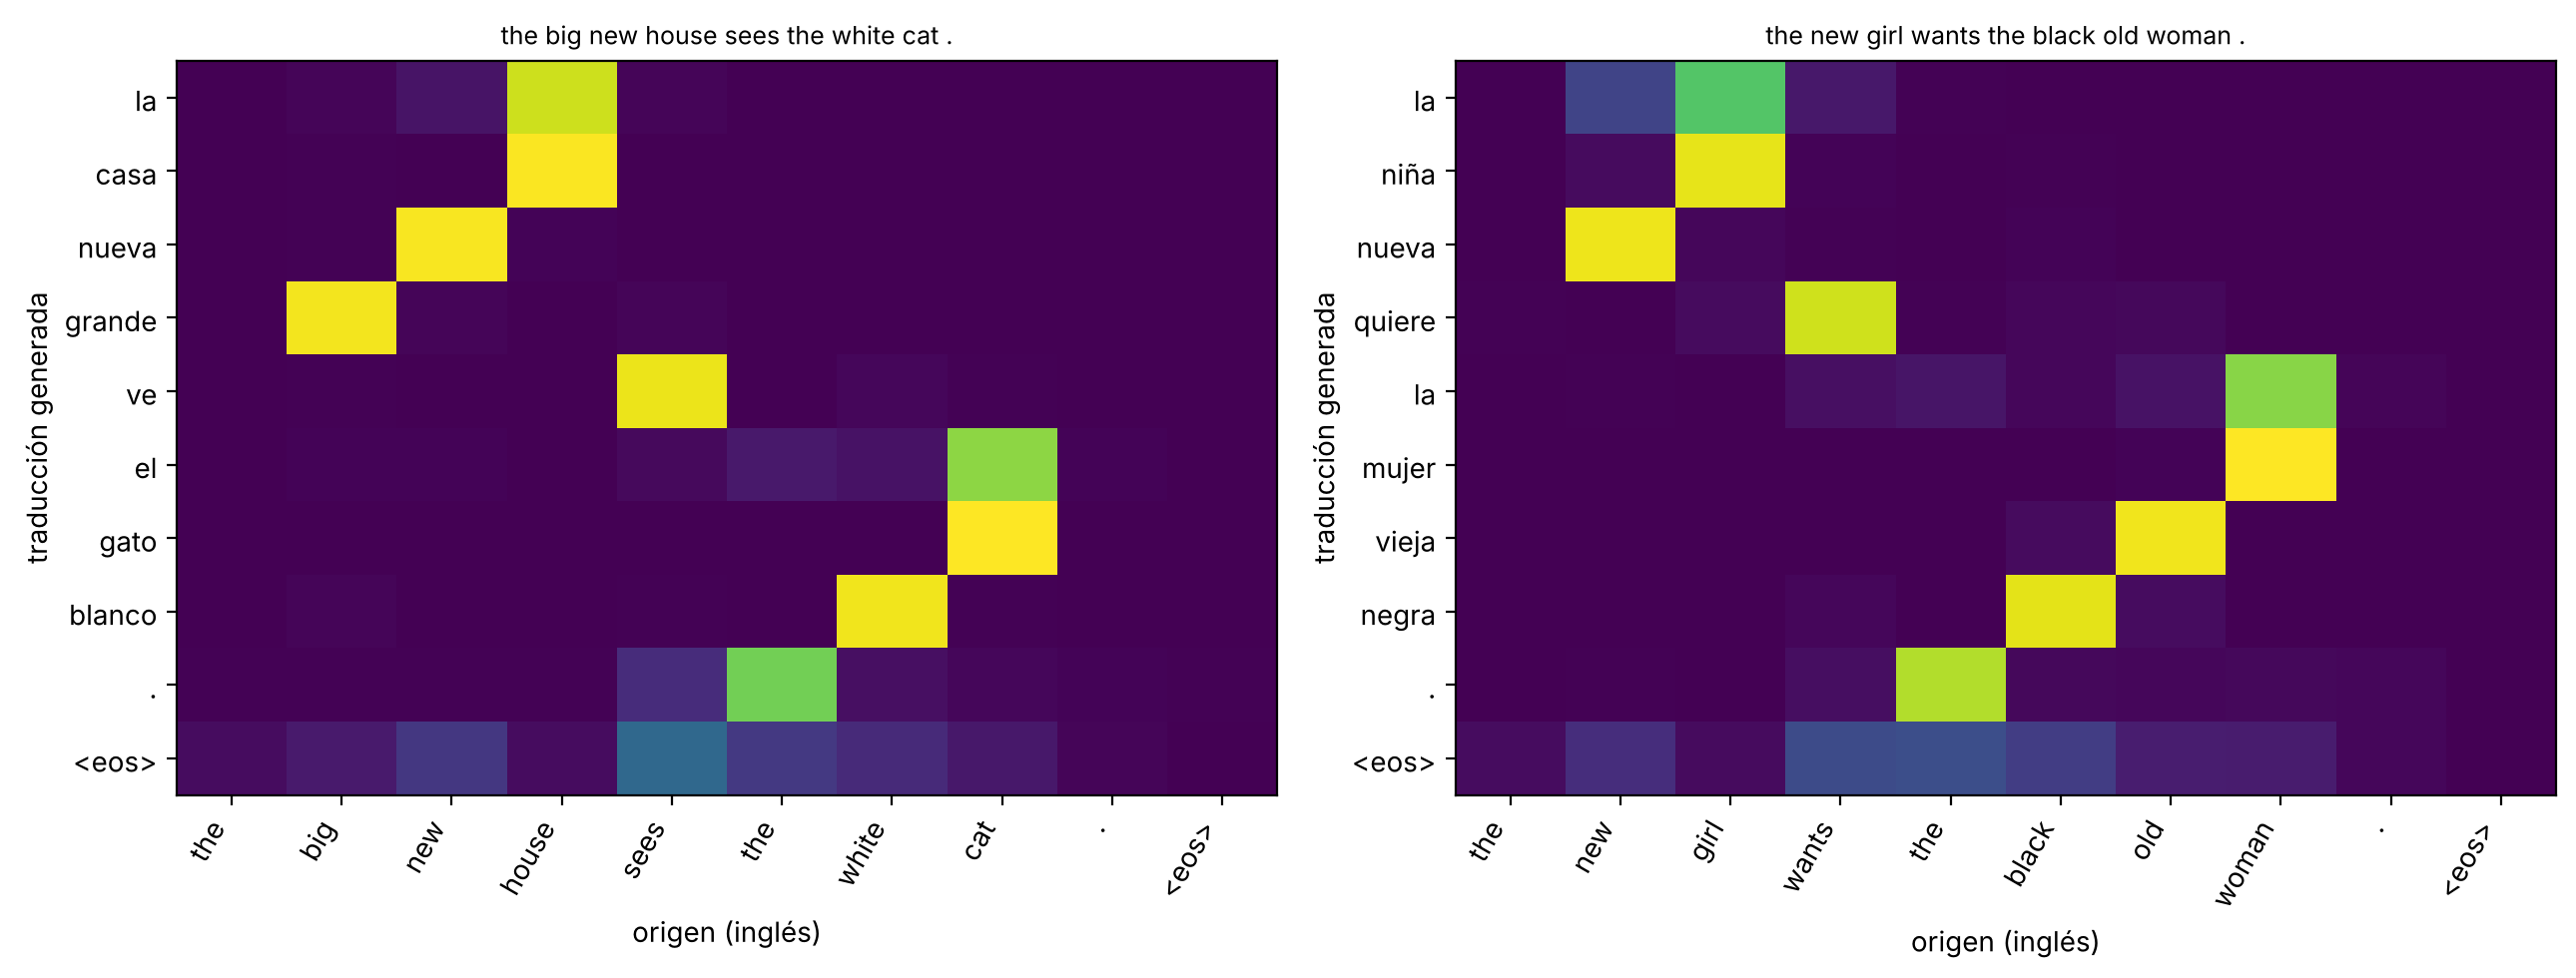

In [12]:
def plot_attention(model, src_tokens, ax=None):
    src = torch.tensor([src_vocab.encode(src_tokens) + [EOS_ID]]).to(DEVICE)
    ids, att = model.generate(src, torch.tensor([src.size(1)]).to(DEVICE), max_len=MAX_LEN + 10)
    out = tgt_vocab.decode(ids[0]) + [EOS]
    A = att[0, :len(out), :].cpu().numpy()
    ax = ax or plt.gca()
    ax.imshow(A, cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(src_tokens) + 1)); ax.set_xticklabels(src_tokens + [EOS], rotation=60, ha="right")
    ax.set_yticks(range(len(out))); ax.set_yticklabels(out)
    ax.set_xlabel("origen (inglés)"); ax.set_ylabel("traducción generada")
    return out, A

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, i in zip(axes, [3, 11]):
    s, _ = test_pairs[i]
    out, A = plot_attention(model_attn, s, ax)
    ax.set_title(" ".join(s), fontsize=9)
plt.tight_layout(); plt.show()

In [13]:
# Comprobación numérica: cada fila de atención suma 1 y el relleno recibe peso 0
s, _ = test_pairs[0]
src = torch.tensor([src_vocab.encode(s) + [EOS_ID]]).to(DEVICE)
_, att = model_attn.generate(src, torch.tensor([src.size(1)]).to(DEVICE))
print("Forma de la matriz de atención (pasos, Tx):", tuple(att[0].shape))
print("Suma por fila (debe ser 1):", att[0].sum(-1)[:5].tolist())

Forma de la matriz de atención (pasos, Tx): (8, 8)
Suma por fila (debe ser 1): [1.0, 1.0000001192092896, 0.9999998807907104, 1.0, 1.0]


## 7. Conclusiones

**Resultados (corpus sintético, 12 épocas, CPU).**

| | sin atención | con atención |
|---|---|---|
| Parámetros | 375 526 | 541 030 |
| Pérdida de validación tras 1 época | 2.307 | 0.0015 |
| Pérdida de validación tras 12 épocas | 0.0077 | 0.0000 |
| BLEU en test | 99.91 | 100.00 |
| Frases exactas en test | 99.7 % | 100 % |

- **Convergencia.** El modelo con atención aprende la tarea casi desde la primera época. El baseline necesita unas 9 épocas para bajar de 0.05 de pérdida de validación, porque debe comprimir toda la frase en un único vector antes de empezar a decodificar.
- **Alineación.** Las matrices $\alpha_{ij}$ muestran lo que se esperaba: el decodificador atiende al sustantivo cuando genera el artículo (necesita su género), al sustantivo al emitirlo y a los adjetivos en orden inverso. Es una alineación suave **no monótona**, que el modelo ha aprendido sin ninguna supervisión de alineación.
- **Verificaciones.** Cada fila de $\alpha$ suma 1 y las posiciones de relleno reciben peso 0.
- **Limitaciones.** En este corpus las frases son cortas (6 a 10 tokens), así que el baseline también llega casi al 100 % y la diferencia final es mínima. La ventaja de la atención en *calidad* se espera sobre todo con frases largas, como las de Europarl. Para comprobarlo basta colocar los ficheros paralelos de Europarl en la carpeta del notebook (variables `SRC_FILE` y `TGT_FILE`) y aumentar `HID_DIM`, `EMB_DIM` y `EPOCHS`; el resto del código no cambia. Esa ejecución no se ha hecho aquí.
- **Coste.** La atención añade parámetros (la capa $W_1$ y $v_a$, y la entrada ampliada del decodificador) y cálculo, ya que el score se calcula para los $T_x$ elementos en cada paso del decodificador.